# 第 33 章：互换再探

本笔记本重算本章每个算例，并重新生成本章的图。参数取自正文，每个数字都与正文印出的数值并列打印，数字一旦偏离就会显现，而不会悄悄出错。

| 小节 | 复现的内容 | 例 |
|---|---|---|
| 1 | 摊还互换，以及平均期限捷径的误差 | 33.1 |
| 2 | 后置凸性，转换之前与之后 | 33.2 |
| 3 | CMS：调整的水平，$G$ 含本金 | 33.3 |
| 4 | 区间累计作为两个数字期权之差 | 33.4 |
| 5 | 可取消互换里的百慕大，年金化 | 33.5 |
| 6 | 取均价对波动率做了什么 | 33.6、图 33.1 |
| 7 | 可重置的交叉货币互换，以及一个取平均的坑 | 33.7 |
| 8 | 同比通胀，以及给它定日的季节性 | 33.8、图 33.2 |
| 9 | 一个权益互换利差背后的四项成本 | 33.9 |

若只读一节，读第 7 节。该节的表只列出十个付款日中的三个，平均值却按全部十个计算；只对列出的三行取平均，得到的数与印出的数值接近到足以蒙混过目测，却是错的。本笔记本正是为发现这类错误而设。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

N = norm.cdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """Print a computed value beside the one the chapter prints. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.4f   book %11.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))

## 1. 摊还互换与平均期限捷径：例 33.1

这笔互换在十年里从 100 线性摊还到零。它的平价利率就是例中给出的比值：贴现后的本金偿还额，除以按名义本金加权的年金因子。

捷径是把它当作一笔期限为其加权平均期限的子弹型互换来定价，而它失效的理由值得点明：这笔互换是 10 笔子弹型互换的组合，平价利率按年金因子为各期限加权，因此两种平均期限都把均值放得太早，误差是曲线斜率的一阶量；只有平坦的曲线才使捷径精确。

注意两种平均期限。按未偿名义本金对付款日加权得到 4.0 年；按已偿本金加权（这是债券市场里*加权平均期限*的含义）得到 5.5 年。惯例确定之前，捷径的误差甚至无法定义。

amortizing par rate, %                               3.8386   book      3.8386   ok
bullet 10-year par rate, %                           4.0187   book      4.0187   ok
bullet 5-year par rate, %                            3.7432   book      3.7432   ok
bullet 4-year par rate, %                            3.6576   book      3.6576   ok
average life, weighted by notional outstanding       4.0000   book      4.0000   ok
average life, weighted by principal repaid           5.5000   book      5.5000   ok
the two definitions differ by, years                 1.5000   book      1.5000   ok
the shortcut's error at 4.0 years, bp              -18.0941   book    -18.1000   ok

n      zero %       bullet par %
1      3.2000       3.2000      
2      3.4000       3.3967      
3      3.5500       3.5424      
4      3.6700       3.6576      
5      3.7600       3.7432      
6      3.8400       3.8181      
7      3.9100       3.8827      
8      3.9700       3.9375      
9      4.0200       3.9827    

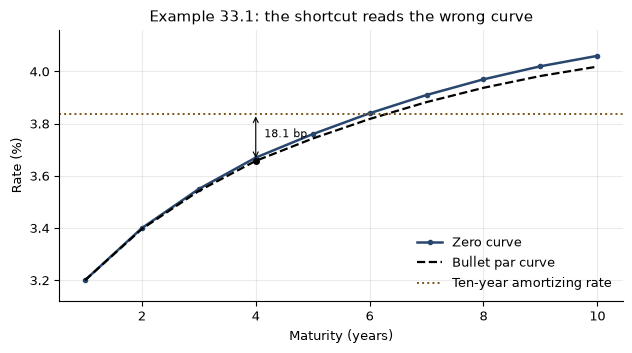

the amortizing rate lies above the 5y bullet         1.0000   book      1.0000   ok
and below the 10y bullet                             1.0000   book      1.0000   ok


In [2]:
# The zero curve Example 33.1 states: annually compounded, one rate per year out to ten.
ZERO = np.array([3.20, 3.40, 3.55, 3.67, 3.76, 3.84, 3.91, 3.97, 4.02, 4.06]) / 100.0
YEARS = np.arange(1, 11)


def zdf(t):
    """Discount factor from the annually compounded zero rate at integer year t."""
    return (1.0 + ZERO[t - 1]) ** -t


def bullet_par(n):
    d = np.array([zdf(t) for t in range(1, n + 1)])
    return 100.0 * (1.0 - d[-1]) / d.sum()


def amort_par(n=10):
    """Par rate of a swap amortizing linearly from 100 to zero."""
    notional = 100.0 * (n - np.arange(n)) / n              # 100, 90, ..., 10
    d = np.array([1.0] + [zdf(t) for t in range(1, n + 1)])
    return 100.0 * (notional * (d[:-1] - d[1:])).sum() / (notional * d[1:]).sum()


AMORT_RATE = amort_par()
show("amortizing par rate, %", AMORT_RATE, 3.8386)
show("bullet 10-year par rate, %", bullet_par(10), 4.0187)
show("bullet 5-year par rate, %", bullet_par(5), 3.7432)
show("bullet 4-year par rate, %", bullet_par(4), 3.6576)

# Two quantities are both called a weighted average life and the example's number depends on which.
notional = 100.0 * (10 - np.arange(10)) / 10.0
repaid = np.full(10, 10.0)
wal_outstanding = (YEARS * notional).sum() / notional.sum()
wal_repaid = (YEARS * repaid).sum() / repaid.sum()
show("average life, weighted by notional outstanding", wal_outstanding, 4.0)
show("average life, weighted by principal repaid", wal_repaid, 5.5)
show("the two definitions differ by, years", wal_repaid - wal_outstanding, 1.5)

show("the shortcut's error at 4.0 years, bp", 100 * (bullet_par(4) - AMORT_RATE), -18.1, 0.05)

print()
print("%-6s %-12s %-12s" % ("n", "zero %", "bullet par %"))
for n in YEARS:
    print("%-6d %-12.4f %-12.4f" % (n, 100 * ZERO[n - 1], bullet_par(n)))

# ------------------------------------------------- the panel inside Example 33.1
# The zero curve, the bullet par curve it implies, and the amortizing swap's rate as a level --
# a ten-year swap has one rate, so it is a horizontal line and not a point on the par curve.
# The shortcut reads the par curve at the 4.0-year average life; the gap to the level is the error.
par_curve = np.array([bullet_par(n) for n in YEARS])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(YEARS, 100 * ZERO, color=BLUE, lw=1.8, marker="o", ms=3, label="Zero curve")
ax.plot(YEARS, par_curve, color="black", lw=1.6, ls="--", label="Bullet par curve")
ax.axhline(AMORT_RATE, color=AMBER, lw=1.4, ls=":", label="Ten-year amortizing rate")
ax.annotate("", xy=(4, bullet_par(4)), xytext=(4, AMORT_RATE),
            arrowprops=dict(arrowstyle="<->", lw=0.8, color="black"))
ax.annotate("%.1f bp" % (100 * (AMORT_RATE - bullet_par(4))),
            xy=(4.15, 0.5 * (AMORT_RATE + bullet_par(4))), fontsize=8)
ax.plot([4], [bullet_par(4)], "o", color="black", ms=4)
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)")
ax.set_ylim(3.12, 4.16); ax.set_title("Example 33.1: the shortcut reads the wrong curve")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

show("the amortizing rate lies above the 5y bullet", float(AMORT_RATE > bullet_par(5)), 1.0, 0.5)
show("and below the 10y bullet", float(AMORT_RATE < bullet_par(10)), 1.0, 0.5)

## 2. 后置凸性，转换之前与之后：例 33.2

式 (33.1) 就是这项调整：$F^2\sigma^2\tau T/(1+F\tau)$。在 LIBOR 下，利率在计息期开始时观察、也在开始时支付，因此相对于该利率自己的计息期，这笔支付是提前的，于是在支付测度下该远期不是鞅。

后置复利的 SOFR 利率在其计息期结束时确定并在那时支付，因此这种错配根本不出现。留下来的是观察期结束与支付日之间两个营业日的延迟。这使付款延后而非提前，因此调整为负；其大小仍由同一个公式给出，只是把 $\tau$ 从半年缩短为两天。

两者大小之比约为 $\tau_{\text{旧}}/\tau_{\text{新}}$，所以它不反映利率波动率的任何信息：$\sigma$ 约掉了。本章从中得出的正是这一点。

In [3]:
F_A, TAU_A, SIG_A = 0.035, 0.5, 0.25


def arrears_adj(T, tau=TAU_A):
    """Equation (33.1): F^2 sigma^2 tau T / (1 + F tau), the in-arrears convexity adjustment."""
    return F_A ** 2 * SIG_A ** 2 * tau * T / (1.0 + F_A * tau)


print("%-8s %-14s %-16s" % ("T", "adj (bp)", "adjusted rate %"))
for T, bp, rate in ((0.5, 0.19, 3.5019), (1.0, 0.38, 3.5038), (2.0, 0.75, 3.5075),
                    (5.0, 1.88, 3.5188), (10.0, 3.76, 3.5376)):
    show("T = %4.1fy, adjustment in bp" % T, 1e4 * arrears_adj(T), bp, 5e-3)
    show("T = %4.1fy, adjusted rate %%" % T, 100 * (F_A + arrears_adj(T)), rate)
    print("%-8.1f %-14.2f %-16.4f" % (T, 1e4 * arrears_adj(T), 100 * (F_A + arrears_adj(T))))

# After the transition the accrual mismatch is gone and the only timing left is the payment lag:
# two business days on a 252-day year. A payment two days AFTER the rate is determined is a deferral,
# so the adjustment is negative (Chapter 30's timing case); its size is the same formula with tau = LAG.
LAG = 2.0 / 252.0
print()
print("%-8s %-18s" % ("T", "two-day lag (bp)"))
for T, bp in ((1.0, -0.0061), (5.0, -0.0304), (10.0, -0.0607)):
    show("T = %4.1fy, two-day lag in bp (negative)" % T, -1e4 * arrears_adj(T, LAG), bp, 5e-4)
    print("%-8.1f %-18.4f" % (T, -1e4 * arrears_adj(T, LAG)))

ratio = arrears_adj(10.0) / arrears_adj(10.0, LAG)        # the ratio of the two sizes
show("how much smaller at ten years, times", ratio, 62.0, 0.6)
print()
print("该比值除一个 (1+F tau) 因子外即为 tau_old / tau_new = %.1f / %.4f，与波动率无关："
      % (TAU_A, LAG))
print("sigma 被约去。小 %.1f 倍是日历决定的事实。" % ratio)

T        adj (bp)       adjusted rate % 
T =  0.5y, adjustment in bp                          0.1881   book      0.1900   ok
T =  0.5y, adjusted rate %                           3.5019   book      3.5019   ok
0.5      0.19           3.5019          
T =  1.0y, adjustment in bp                          0.3762   book      0.3800   ok
T =  1.0y, adjusted rate %                           3.5038   book      3.5038   ok
1.0      0.38           3.5038          
T =  2.0y, adjustment in bp                          0.7525   book      0.7500   ok
T =  2.0y, adjusted rate %                           3.5075   book      3.5075   ok
2.0      0.75           3.5075          
T =  5.0y, adjustment in bp                          1.8811   book      1.8800   ok
T =  5.0y, adjusted rate %                           3.5188   book      3.5188   ok
5.0      1.88           3.5188          
T = 10.0y, adjustment in bp                          3.7623   book      3.7600   ok
T = 10.0y, adjusted rate %             

## 3. CMS：例 33.3

第 30.5 节的调整是 $-\tfrac12 S_0^2\sigma^2 T\,G''(S_0)/G'(S_0)$，其中 $G$ 按该节的定义是票面利率为 $S_0$ 的十年期债券的价格，**含本金**，因此 $G(S_0) = 1$。下面一格用中心差分求出 $G'$ 与 $G''$，重新算出调整的水平：距定盘每多一年 3.6507 bp。

这项惯例值得固定下来，因为它会改变答案。只用票息构造的 $G$ 给出每年 2.72 bp，约少四分之一；这一格把它也打印出来。

也检查了结构：该调整随付款日线性增长，而公平固定利率是各调整后利率按年金加权的平均。这足以发现交易台最容易犯的错误：把调整用在了错误的付款上，或者对它们做了等权平均。

In [4]:
S_C, SIG_C, DISC_C, N_C = 0.034, 0.25, 0.032, 10

# Section 30.5's adjustment is -(1/2) S0^2 sigma^2 T G''(S0)/G'(S0), with G the annuity mapping
# function: the ten-year annual bond at coupon S0, priced at yield y, INCLUDING its principal, as
# that section defines it, so G(S0) = 1. G' and G'' are taken by central differences. Leaving the
# principal out gives 2.72 bp a year, so the convention moves the level by about a quarter.


def G_bond(y, principal=True):
    """The ten-year annual bond at coupon S_C, priced at yield y, per 1 of face."""
    t = np.arange(1, N_C + 1)
    return (S_C / (1.0 + y) ** t).sum() + ((1.0 + y) ** -N_C if principal else 0.0)


def G_slopes(principal=True, h=1e-5):
    g0, up, dn = G_bond(S_C, principal), G_bond(S_C + h, principal), G_bond(S_C - h, principal)
    return (up - dn) / (2 * h), (up - 2 * g0 + dn) / h ** 2


def cms_per_year(principal=True):
    g1, g2 = G_slopes(principal)
    return -0.5 * S_C ** 2 * SIG_C ** 2 * g2 / g1


show("G(S0), with the principal", G_bond(S_C), 1.0, 1e-12)
show("G'(S0)", G_slopes()[0], -8.3587)
show("G''(S0)", G_slopes()[1], 84.4709, 5e-3)
ADJ_1Y = cms_per_year()
show("adjustment per year of fixing, bp", 1e4 * ADJ_1Y, 3.6507, 5e-5)
show("the same with a coupons-only G, bp", 1e4 * cms_per_year(False), 2.72, 5e-3)
adj = ADJ_1Y * np.arange(1, N_C + 1)

print()
print("%-10s %-14s %-16s" % ("payment", "adj (bp)", "adjusted rate %"))
for T, bp, rate in ((1, 3.65, 3.4365), (3, 10.95, 3.5095), (5, 18.25, 3.5825),
                    (7, 25.55, 3.6555), (10, 36.51, 3.7651)):
    show("payment %2d, adjustment in bp" % T, 1e4 * adj[T - 1], bp, 5e-3)
    show("payment %2d, adjusted rate %%" % T, 100 * (S_C + adj[T - 1]), rate)
    print("%-10d %-14.2f %-16.4f" % (T, 1e4 * adj[T - 1], 100 * (S_C + adj[T - 1])))

w = (1.0 + DISC_C) ** -np.arange(1, N_C + 1)
fair = (w * (S_C + adj)).sum() / w.sum()
show("fair fixed rate with adjustments, %", 100 * fair, 3.5913)
show("fair fixed rate ignoring them, %", 100 * S_C, 3.4000)
show("the difference, bp", 1e4 * (fair - S_C), 19.13, 5e-3)

print()
print("该调整随 T 线性增长，因此它按年金加权的平均接近、但低于")
print("简单平均：加权 %.2f bp 对不加权 %.2f bp，因为贴现"
      % (1e4 * (fair - S_C), 1e4 * adj.mean()))
print("把更多权重放在靠前的付款上，而那里的调整最小。")

G(S0), with the principal                            1.0000   book      1.0000   ok
G'(S0)                                              -8.3587   book     -8.3587   ok
G''(S0)                                             84.4709   book     84.4709   ok
adjustment per year of fixing, bp                    3.6507   book      3.6507   ok
the same with a coupons-only G, bp                   2.7233   book      2.7200   ok

payment    adj (bp)       adjusted rate % 
payment  1, adjustment in bp                         3.6507   book      3.6500   ok
payment  1, adjusted rate %                          3.4365   book      3.4365   ok
1          3.65           3.4365          
payment  3, adjustment in bp                        10.9521   book     10.9500   ok
payment  3, adjusted rate %                          3.5095   book      3.5095   ok
3          10.95          3.5095          
payment  5, adjustment in bp                        18.2535   book     18.2500   ok
payment  5, adjusted rate %   

## 4. 区间累计：例 33.4

票息只在利率位于区间内的那些天计息，因此它是一串数字期权，第 2 年至第 2.25 年这一季度的 90 个观察日各对应两个；期望计息比例是两个数字期权之差在各日上的平均。在远期测度下该利率服从对数正态，所以每一个都是

$$P(R_{T_i} < K) = N(-d_2), \qquad d_2 = \frac{\ln(F/K) - \sigma^2 T_i/2}{\sigma\sqrt{T_i}}$$

增强后的票息就是普通票息除以这个比例，最醒目的 254 个基点即由此而来。随后第二张表在别的波动率上对同一个票息重新估值，由此可见：这份增强是空头 vega 头寸，而不是馈赠。

In [5]:
F_R, LO, HI = 0.035, 0.025, 0.045
TS = 2.0 + np.arange(1, 91) / 360.0      # 90 daily observations over the quarter from year 2


def d2_of(K, sig, T, F=F_R):
    """The example's displayed form: d_2 = [ln(F/K) - sigma^2 T/2] / (sigma sqrt(T))."""
    return (np.log(F / K) - sig ** 2 * T / 2.0) / (sig * np.sqrt(T))


def below(K, sig):
    """P(R_T < K) = N(-d_2) for each observation day, averaged over the 90 days."""
    return np.mean(N(-d2_of(K, sig, TS)))


def accrual(sig):
    return below(HI, sig) - below(LO, sig)


# The days are not interchangeable: the in-range probability falls through the quarter.
day = lambda T: N(-d2_of(HI, 0.25, T)) - N(-d2_of(LO, 0.25, T))
show("in-range probability, first day", day(TS[0]), 0.5931)
show("in-range probability, last day", day(TS[-1]), 0.5655)
show("one observation at two years", day(2.0), 0.5934)


show("P(rate < 2.50%)", below(LO, 0.25), 0.2294)
show("P(rate < 4.50%)", below(HI, 0.25), 0.8084)
FRAC = accrual(0.25)
show("P(inside) -- the expected accrual fraction", FRAC, 0.5790)

COUPON = 100 * F_R / FRAC
show("the enhanced coupon, %", COUPON, 6.0447)
show("the enhancement in bp", 100 * (COUPON - 100 * F_R), 254.0, 0.5)
show("understated by one observation at two years, bp", 100 * (COUPON - 100 * F_R / day(2.0)), 15.0, 0.5)
show("the enhancement as a % of the vanilla", 100 * (COUPON / (100 * F_R) - 1.0), 73.0, 0.5)

print()
print("%-14s %-18s %-22s" % ("realized vol", "accrual fraction", "coupon received %"))
for sig, f_want, v_want in ((0.15, 0.8194, 4.9532), (0.20, 0.6865, 4.1500), (0.25, 0.5790, 3.5000),
                            (0.35, 0.4297, 2.5976), (0.50, 0.2996, 1.8113)):
    f = accrual(sig)
    show("realized vol %2.0f%%, accrual fraction" % (100 * sig), f, f_want)
    show("realized vol %2.0f%%, coupon received %%" % (100 * sig), COUPON * f, v_want)
    print("%-14.0f %-18.4f %-22.4f" % (100 * sig, f, COUPON * f))

show("worth the vanilla 3.50% at the pricing vol", COUPON * FRAC, 100 * F_R, 1e-9)

# The vega is the slope of that last column, and it is negative everywhere -- which is the example's
# whole claim. Differencing it is enough to see the sign and the steepest point.
vols = np.linspace(0.10, 0.60, 501)
curve = COUPON * np.array([accrual(v) for v in vols])
slope = np.gradient(curve, vols)
show("the coupon's slope in vol is negative throughout", float(np.all(slope < 0)), 1.0, 0.5)
print()
print("在 %.1f%% 波动率处最陡，远低于票据定价所用的 %.0f%%。"
      % (100 * vols[np.argmin(slope)], 100 * 0.25))

in-range probability, first day                      0.5931   book      0.5931   ok
in-range probability, last day                       0.5655   book      0.5655   ok
one observation at two years                         0.5934   book      0.5934   ok
P(rate < 2.50%)                                      0.2294   book      0.2294   ok
P(rate < 4.50%)                                      0.8084   book      0.8084   ok
P(inside) -- the expected accrual fraction           0.5790   book      0.5790   ok
the enhanced coupon, %                               6.0447   book      6.0447   ok
the enhancement in bp                              254.4736   book    254.0000   ok
understated by one observation at two years, bp      14.6781   book     15.0000   ok
the enhancement as a % of the vanilla               72.7067   book     73.0000   ok

realized vol   accrual fraction   coupon received %     
realized vol 15%, accrual fraction                   0.8194   book      0.8194   ok
realized vol 15%,

## 5. 可取消互换：例 33.5

可取消互换是普通互换加上一份百慕大互换期权，本例要做的是换算：以货币计的期权价值除以年金因子，就成为固定端上的利差。这 32.23 个基点只是第一次迭代：期权的执行利率就是算出的利率，正确的利率是不动点 4.5339%（比平价利率高 54.8 个基点）。这一步要用第 31 章的树，由 `tools/verify/ch31-tree-products.py` 核对。

百慕大的价值、年金因子与普通互换的平价利率都来自第 31 章的格点例子，所以在这里它们是输入而不是结果。这次换算使一项单看期权价值无法进行的比较成为可能：与所报产品自身的买卖价差相比。

In [6]:
# Three inputs, all from Chapter 31's lattice examples: the annuity of the six remaining years, the
# Bermudan's value, and the vanilla par rate. The point of the example is the conversion, not the
# option pricing, so the Bermudan is taken as given and annuitized.
ANNUITY, BERMUDAN, PAR6 = 5.272406, 1.6995, 3.9862

SPREAD = BERMUDAN / ANNUITY            # per 100 of notional, so already in percent
show("spread on the fixed leg, bp", 100 * SPREAD, 32.23, 5e-3)
show("cancellable swap fixed rate, %", PAR6 + SPREAD, 4.3085)

# Example 31.9 found the Bermudan's value spanning 13.1% across mean-reversion assumptions that all
# reproduce the calibrating European exactly. Annuitized, that span is what a quoting desk faces.
show("Example 31.9's 13.1% span, annuitized, in bp", 0.131 * 100 * SPREAD, 4.2, 0.05)

print()
print("一个报价利率带着 %.2f bp 的模型歧义，而买卖价差不到 1 bp。"
      % (0.131 * 100 * SPREAD))
print("这项歧义是价差的数倍，因此无法被吸收进报价里：")
print("它只能被计提准备、被对冲，或者被拒绝。")

spread on the fixed leg, bp                         32.2339   book     32.2300   ok
cancellable swap fixed rate, %                       4.3085   book      4.3085   ok
Example 31.9's 13.1% span, annuitized, in bp         4.2226   book      4.2000   ok

一个报价利率带着 4.22 bp 的模型歧义，而买卖价差不到 1 bp。
这项歧义是价差的数倍，因此无法被吸收进报价里：
它只能被计提准备、被对冲，或者被拒绝。


## 6. 商品取均价：例 33.6，以及图 33.1

$n$ 个等间隔观察点的几何平均（算术平均与之相近），其对数方差是终端的 $(n+1)(2n+1)/6n^2$ 倍，并收敛到 $1/3$，因此波动率收敛到终端的 $1/\sqrt{3}$。

后果按收益形态分岔。取均价在线性收益内部是中性的，所以互换不受影响；在凸收益内部不是中性的，所以它拿掉了一份平值期权 40% 的权利金。交易台若不做调整就拿均价结算期权的隐含波动率去比单点结算的，比的是两个不同的量。

图 33.1 把两幅分图放在一起：第 4 节里区间累计的 vega，以及这个乘子。

n        variance ratio   vol multiplier      
n =  1, variance ratio                               1.0000   book      1.0000   ok
n =  1, volatility multiplier                        1.0000   book      1.0000   ok
1        1.0000           1.0000              
n =  5, variance ratio                               0.4400   book      0.4400   ok
n =  5, volatility multiplier                        0.6633   book      0.6633   ok
5        0.4400           0.6633              
n = 10, variance ratio                               0.3850   book      0.3850   ok
n = 10, volatility multiplier                        0.6205   book      0.6205   ok
10       0.3850           0.6205              
n = 21, variance ratio                               0.3575   book      0.3575   ok
n = 21, volatility multiplier                        0.5979   book      0.5979   ok
21       0.3575           0.5979              
n = 63, variance ratio                               0.3413   book      0.3413   ok
n = 63, v

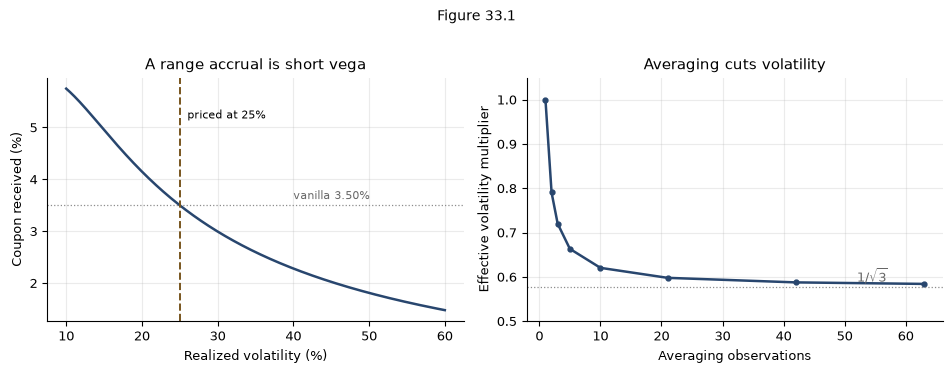


降幅大部分在第五次定盘前就已实现：n = 5 时已为 0.6633，而
极限值为 0.5774，因此定盘次数超过几十次之后再增加，作用甚微。


In [7]:
def var_ratio(n):
    """Var[ln of the average] / Var[ln of the terminal] for n equally spaced fixings."""
    return (n + 1.0) * (2.0 * n + 1.0) / (6.0 * n * n)


print("%-8s %-16s %-20s" % ("n", "variance ratio", "vol multiplier"))
for n, r_want, m_want in ((1, 1.0000, 1.0000), (5, 0.4400, 0.6633), (10, 0.3850, 0.6205),
                          (21, 0.3575, 0.5979), (63, 0.3413, 0.5842)):
    show("n = %2d, variance ratio" % n, var_ratio(n), r_want)
    show("n = %2d, volatility multiplier" % n, np.sqrt(var_ratio(n)), m_want)
    print("%-8d %-16.4f %-20.4f" % (n, var_ratio(n), np.sqrt(var_ratio(n))))

show("the continuous limit, 1/sqrt(3)", 1.0 / np.sqrt(3.0), 0.5774)
show("21 fixings are within this % of the limit",
     100 * (np.sqrt(var_ratio(21)) * np.sqrt(3.0) - 1.0), 3.6, 0.1)


def atm_black(F, sig, T):
    """At-the-money Black: F [N(d) - N(-d)] with d = sigma sqrt(T) / 2."""
    d = 0.5 * sig * np.sqrt(T)
    return F * (N(d) - N(-d))


SPOT, VOL_C, TENOR = 80.0, 0.35, 1.0
EFF = VOL_C * np.sqrt(var_ratio(21))
show("premium on the single fixing", atm_black(SPOT, VOL_C, TENOR), 11.1136)
show("effective volatility on the average, %", 100 * EFF, 20.93, 5e-3)
show("premium on the 21-fixing average", atm_black(SPOT, EFF, TENOR), 6.6669, 5e-3)
show("share of the premium averaging removes, %",
     100 * (1.0 - atm_black(SPOT, EFF, TENOR) / atm_black(SPOT, VOL_C, TENOR)), 40.0, 0.2)

# ------------------------------------------------------------------ Figure 33.1
# Left: the range accrual coupon against the volatility that materializes (Example 33.4) -- the
# picture a prospectus does not contain, since the coupon falls in the quantity the buyer is least
# likely to be forecasting. Right: the averaging multiplier against the number of fixings
# (Example 33.6), which drops almost all the way to 1/sqrt(3) by the first handful.
ns = np.array([1, 2, 3, 5, 10, 21, 42, 63])
mult = np.sqrt(var_ratio(ns.astype(float)))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(9.6, 3.6))
axL.plot(100 * vols, curve, color=BLUE, lw=1.8)
axL.axhline(100 * F_R, color="0.55", lw=0.9, ls=":")
axL.axvline(25.0, color=AMBER, lw=1.4, ls="--")
axL.annotate("priced at 25%", xy=(26, 0.9 * curve.max()), fontsize=8)
axL.annotate("vanilla 3.50%", xy=(40, 100 * F_R + 0.12), fontsize=8, color="0.4")
axL.set_xlabel("Realized volatility (%)"); axL.set_ylabel("Coupon received (%)")
axL.set_title("A range accrual is short vega")

axR.plot(ns, mult, color=BLUE, lw=1.8, marker="o", ms=3.5)
axR.axhline(1.0 / np.sqrt(3.0), color="0.55", lw=0.9, ls=":")
axR.annotate(r"$1/\sqrt{3}$", xy=(52, 1.0 / np.sqrt(3.0) + 0.012), fontsize=9, color="0.4")
axR.set_xlabel("Averaging observations"); axR.set_ylabel("Effective volatility multiplier")
axR.set_ylim(0.5, 1.05); axR.set_title("Averaging cuts volatility")
fig.suptitle("Figure 33.1", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

print()
print("降幅大部分在第五次定盘前就已实现：n = 5 时已为 %.4f，而"
      % np.sqrt(var_ratio(5)))
print("极限值为 %.4f，因此定盘次数超过几十次之后再增加，作用甚微。" % (1 / np.sqrt(3.0)))

## 7. 可重置名义本金的交叉货币互换：例 33.7

名义本金本身是汇率的函数，利息又按它计算，因此每笔支付都是一个利率乘以一个汇率水平，远期利率需要修正 $-F\rho\,\sigma_S\sigma_F T_i$，这正是第 30.6 节的 quanto 形态。

$T_i$ 是决定该笔付款名义本金的*重置日*，即支付日之前半年：过了重置日，汇率水平已经知道，协方差只累积到这一天为止。

**这里的取平均是一个容易出错之处**。例中展示了十个付款日里的三个，并说它的平均是对全部十个取的。这笔互换五年期、每半年支付，所以十个重置日是 $T = 0, 0.5, \ldots, 4.5$，均值为 2.25，而不是所展示三行的重置日均值 2.5。把看得见的三行取平均得到 $-5.63$ bp，与印出的 $-5.06$ 足够接近，像是复现出来了，其实是错的。

In [8]:
F_X, SIG_S, SIG_F = 0.03, 0.10, 0.25


def reset_adj(rho, T):
    """The forward rate's correction on a notional that is itself a function of spot. T is the
    RESET date that fixes the payment's notional, half a year before the payment: after it the FX
    level is known, so the covariance accrues only up to it."""
    return -F_X * rho * SIG_S * SIG_F * T


def half_up(x):
    """Two decimals, ties away from zero, as the chapter's table prints them (-5.625 -> -5.63)."""
    return float(np.sign(x) * np.floor(abs(x) * 100.0 + 0.5 + 1e-9) / 100.0) + 0.0


# Tolerance 1e-2: -1.125, -5.625 and -10.125 are exact ties at two decimals, printed rounded away
# from zero, so half of the last digit would sit exactly on the boundary.
print("%-14s %-12s %-12s %-12s" % ("payment date", "rho = 0", "rho = 0.3", "rho = 0.6"))
for T in (1, 3, 5):
    row = [1e4 * reset_adj(r, T - 0.5) for r in (0.0, 0.3, 0.6)]
    for rho, got, want in zip((0.0, 0.3, 0.6), row, {1: (0.0, -1.13, -2.25),
                                                     3: (0.0, -5.63, -11.25),
                                                     5: (0.0, -10.13, -20.25)}[T]):
        show("rho %.1f, %dy (reset %.1fy), bp" % (rho, T, T - 0.5), got, want, 1e-2)
    print("%-14s %-12.2f %-12.2f %-12.2f" % ("%d year" % T, half_up(row[0]), half_up(row[1]), half_up(row[2])))

# The example shows three of the ten payment dates and averages over all ten. Semiannual for five
# years means payments at 0.5, 1.0, ..., 5.0 and resets half a year earlier, at 0.0, 0.5, ..., 4.5,
# whose mean is 2.25 -- NOT the mean of the three rows shown, whose resets average 2.5. Averaging
# the visible rows gives -5.63 and would look like a reproduction.
DATES = 0.5 * np.arange(0, 10)
show("mean reset date over the ten payments", DATES.mean(), 2.25)
print()
print("%-14s %-12s %-12s %-12s" % ("average", "rho = 0", "rho = 0.3", "rho = 0.6"))
avg = [1e4 * reset_adj(r, DATES).mean() for r in (0.0, 0.3, 0.6)]
for rho, got, want in zip((0.0, 0.3, 0.6), avg, (0.00, -5.06, -10.13)):
    show("rho %.1f, average over all ten resets, bp" % rho, got, want, 1e-2)
print("%-14s %-12.2f %-12.2f %-12.2f" % ("all ten", half_up(avg[0]), half_up(avg[1]), half_up(avg[2])))
print()
print("只把展示的三行取平均得到 %.2f bp，而不是 %.2f。这提醒我们，一张"
      % (half_up(1e4 * np.mean([reset_adj(0.3, t - 0.5) for t in (1, 3, 5)])), half_up(avg[1])))
print("只展示计划表一个子集的表，不能当作整个计划表来取平均。")

payment date   rho = 0      rho = 0.3    rho = 0.6   
rho 0.0, 1y (reset 0.5y), bp                        -0.0000   book      0.0000   ok
rho 0.3, 1y (reset 0.5y), bp                        -1.1250   book     -1.1300   ok
rho 0.6, 1y (reset 0.5y), bp                        -2.2500   book     -2.2500   ok
1 year         0.00         -1.13        -2.25       
rho 0.0, 3y (reset 2.5y), bp                        -0.0000   book      0.0000   ok
rho 0.3, 3y (reset 2.5y), bp                        -5.6250   book     -5.6300   ok
rho 0.6, 3y (reset 2.5y), bp                       -11.2500   book    -11.2500   ok
3 year         0.00         -5.63        -11.25      
rho 0.0, 5y (reset 4.5y), bp                        -0.0000   book      0.0000   ok
rho 0.3, 5y (reset 4.5y), bp                       -10.1250   book    -10.1300   ok
rho 0.6, 5y (reset 4.5y), bp                       -20.2500   book    -20.2500   ok
5 year         0.00         -10.13       -20.25      
mean reset date over the ten

## 8. 同比通胀，以及季节性：例 33.8，以及图 33.2

每笔同比付款都是两个指数水平之比，在较晚的日期支付，因此较早的水平实际上晚了一年才支付，调整就是指数与名义利率之间的协方差：距较早定盘每多一年为 $\rho\,\sigma_I\,\sigma_n$。若利率是确定性的，无论指数波动多大，调整都为零。本章取 $\rho = +0.9$（通胀与名义利率往往同向上升），$\sigma_I = 1.6\%$，$\sigma_n = 1.0$ 个百分点，于是每年 1.44 bp，且为正。第一笔支付不带任何调整，因为它较早的定盘就是基期指数，在起始时已经知道。零息互换在任何期限上都不带，因此两个通胀市场各自独立报价，而不是由一个读出另一个。

图 33.2 随后说明通胀互换为什么必须按月份定价。指数有年度形态，观察窗口若不是整年，会留下一项季节误差，而这项误差**大于例中刚刚算出的凸性调整**，因此定日惯例比数学更重要。

adjustment per year to the earlier fixing, bp        1.4400   book      1.4400   ok

year     adj (bp)        
year  1, adjustment in bp                            0.0000   book      0.0000   ok
1        0.00            
year  2, adjustment in bp                            1.4400   book      1.4400   ok
2        1.44            
year  5, adjustment in bp                            5.7600   book      5.7600   ok
5        5.76            
year 10, adjustment in bp                           12.9600   book     12.9600   ok
10       12.96           
averaged over ten years, bp                          6.4800   book      6.4800   ok

零息互换完全不带这一项，因此两个通胀市场
各自独立报价，而不是由一个读出另一个。


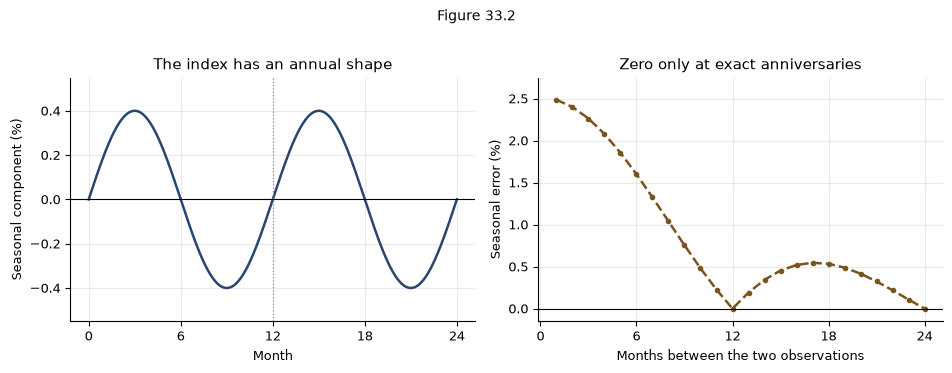

the error vanishes at twelve months                  0.0000   book      0.0000   ok
and at twenty-four                                   0.0000   book      0.0000   ok
worst case at one month, %                           2.4847   book      2.4850   ok

相隔一个月时，年化误差是 2.48%，是例中所算凸性调整的 19 倍，
因此定日比凸性更重要。


In [9]:
# The earlier fixing I_{k-1} is in effect paid a year late, so the adjustment is a covariance between
# the index and the nominal rate over the time to that fixing: rho sigma_I sigma_n per year (first
# order). With deterministic rates it is zero, however volatile the index. Inflation and nominal
# rates tend to rise together, so rho > 0 and the adjustment is positive. The first payment's earlier
# fixing is the base index, known at inception, so it carries none.
RHO_IN = 0.9             # correlation between the index and the one-year nominal rate
SIG_IDX = 0.016          # index volatility
SIG_NOM = 0.010          # normal volatility of the one-year nominal rate: 1.0 percentage point
PER_YEAR = RHO_IN * SIG_IDX * SIG_NOM

show("adjustment per year to the earlier fixing, bp", 1e4 * PER_YEAR, 1.44, 5e-3)
print()
print("%-8s %-16s" % ("year", "adj (bp)"))
for T, want in ((1, 0.00), (2, 1.44), (5, 5.76), (10, 12.96)):
    show("year %2d, adjustment in bp" % T, 1e4 * PER_YEAR * (T - 1), want, 5e-3)
    print("%-8d %-16.2f" % (T, 1e4 * PER_YEAR * (T - 1)))

ten = np.arange(1, 11)
show("averaged over ten years, bp", 1e4 * PER_YEAR * (ten - 1).mean(), 6.48, 5e-3)
print()
print("零息互换完全不带这一项，因此两个通胀市场")
print("各自独立报价，而不是由一个读出另一个。")

# ------------------------------------------------------------------ Figure 33.2
# Left: an illustrative seasonal component s(m) = A sin(2 pi m / 12), amplitude 0.4%. Not market
# data. Right: the worst-case annualized error from an observation window that is not a whole number
# of years, (12/n) * 2A * |sin(pi n / 12)| -- zero only at exact anniversaries.
AMP = 0.4
months = np.linspace(0.0, 24.0, 481)
season = AMP * np.sin(2 * np.pi * months / 12.0)
n_months = np.arange(1, 25)
worst = (12.0 / n_months) * 2 * AMP * np.abs(np.sin(np.pi * n_months / 12.0))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(9.6, 3.6))
axL.plot(months, season, color=BLUE, lw=1.8)
axL.axhline(0.0, color="black", lw=0.8)
axL.axvline(12.0, color="0.55", lw=0.9, ls=":")
axL.set_xlabel("Month"); axL.set_ylabel("Seasonal component (%)")
axL.set_xticks([0, 6, 12, 18, 24]); axL.set_ylim(-0.55, 0.55)
axL.set_title("The index has an annual shape")

axR.plot(n_months, worst, color=AMBER, lw=1.8, ls="--", marker="o", ms=3)
axR.axhline(0.0, color="black", lw=0.8)
axR.set_xlabel("Months between the two observations"); axR.set_ylabel("Seasonal error (%)")
axR.set_xticks([0, 6, 12, 18, 24]); axR.set_ylim(-0.15, 2.75)
axR.set_title("Zero only at exact anniversaries")
fig.suptitle("Figure 33.2", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

show("the error vanishes at twelve months", worst[11], 0.0, 1e-12)
show("and at twenty-four", worst[23], 0.0, 1e-12)
show("worst case at one month, %", worst[0], 2.485, 5e-3)
print()
print("相隔一个月时，年化误差是 %.2f%%，是例中所算凸性调整的 %.0f 倍，"
      % (worst[0], worst[0] / (1e2 * PER_YEAR * 9)))
print("因此定日比凸性更重要。")

## 9. 权益互换的利差：例 33.9

一个报价数字背后有四项成本，而哪几项计入取决于方向。为客户多头对冲时，交易商买入股票，承担融资、通过预提税发生的股息漏损与资产负债表占用成本；为客户空头对冲时，它借入股票并卖出，收到现金而不是需要现金，手里也没有股息，剩下的只有借券费与资产负债表占用成本。计算并不难，要点在于结构：每一项对交易商都可观察，而没有一项对客户可观察。

股息那一项是最尖锐的情形。预提税取决于交易商自身的税收协定状况，而不取决于指数，因此两家交易商为以同一指数为标的的同一笔互换报价时，成本确实不同，而客户无从分辨是哪一个。

In [10]:
# Four costs, each observable to the dealer and none of them to the client. The arithmetic is
# trivial; the point is that one quoted number is a sum, and which terms enter depends on the side.
# A dealer hedging a client's short sells borrowed stock and receives cash, so it has no funding
# cost and no dividends to lose to withholding: only borrow and balance sheet remain.
FUNDING, BALANCE_SHEET, BORROW = 25.0, 15.0, 40.0
DIV_YIELD, WITHHOLDING = 0.020, 0.15

leakage = 1e4 * WITHHOLDING * DIV_YIELD
show("dividend leakage: 15% withholding on 2.0%, bp", leakage, 30.0, 1e-9)
show("quoted spread, synthetic long, bp", FUNDING + leakage + BALANCE_SHEET, 70.0, 1e-9)
show("quoted spread, synthetic short, bp",
     BORROW + BALANCE_SHEET, 55.0, 1e-9)

print()
print("%-26s %-10s" % ("component", "bp"))
for name, bp in (("funding (long)", FUNDING), ("dividend leakage (long)", leakage),
                 ("balance sheet (both)", BALANCE_SHEET), ("borrow (short)", BORROW)):
    print("%-26s %-10.1f" % (name, bp))
print("%-26s %-10.1f" % ("total, synthetic long", FUNDING + leakage + BALANCE_SHEET))
print("%-26s %-10.1f" % ("total, synthetic short", BORROW + BALANCE_SHEET))
print()
print("股息那一项是客户算不出来的，因为预提税率")
print("取决于交易商自身的税收协定状况，而不取决于指数。")

dividend leakage: 15% withholding on 2.0%, bp       30.0000   book     30.0000   ok
quoted spread, synthetic long, bp                   70.0000   book     70.0000   ok
quoted spread, synthetic short, bp                  55.0000   book     55.0000   ok

component                  bp        
funding (long)             25.0      
dividend leakage (long)    30.0      
balance sheet (both)       15.0      
borrow (short)             40.0      
total, synthetic long      70.0      
total, synthetic short     55.0      

股息那一项是客户算不出来的，因为预提税率
取决于交易商自身的税收协定状况，而不取决于指数。


## 什么复现了，以及该从这里带走什么

若下面一格报告每一个数字都得到复现，本笔记本即与本章一致。

这里有两个值得养成的习惯。**检查比值不可能依赖什么**：后置调整六十倍的下降就是 $\tau_{\text{旧}}/\tau_{\text{新}}$，波动率从中精确地约掉了，因此本章可以说，转换对利率波动率毫无影响。另一个是**绝不要把计划表的一部分当作整个计划表来取平均**：第 7 节里看得见的三行，其平均与正确答案接近到足以通过一次目测。

In [11]:
if BAD:
    print("有 %d 个数字与正文不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中的每个数字都与正文一致")

本笔记本中的每个数字都与正文一致
